## 1. Imports and project paths


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
from pathlib import Path

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

# Notebook root ya notebooks/ folder se run ho, dono cases handle honge.
possible_roots = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = None

for path in possible_roots:
    if (path / "data" / "raw" / "online_retail_II.xlsx").exists():
        PROJECT_ROOT = path
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "online_retail_II.xlsx nahi mila. File ko project/data/raw/ mein rakho."
    )

RAW_FILE = PROJECT_ROOT / "data" / "raw" / "online_retail_II.xlsx"
INTERIM_DIR = PROJECT_ROOT / "data" / "interim"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

INTERIM_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Raw file:", RAW_FILE)
print("Interim output:", INTERIM_DIR)
print("Processed output:", PROCESSED_DIR)

Project root: d:\loyality_reward_optimization
Raw file: d:\loyality_reward_optimization\data\raw\online_retail_II.xlsx
Interim output: d:\loyality_reward_optimization\data\interim
Processed output: d:\loyality_reward_optimization\data\processed


## 2. Load both sheets and combine


In [2]:
df_2009 = pd.read_excel(RAW_FILE, sheet_name="Year 2009-2010")
df_2010 = pd.read_excel(RAW_FILE, sheet_name="Year 2010-2011")

print("Year 2009-2010 shape:", df_2009.shape)
print("Year 2010-2011 shape:", df_2010.shape)

df_2009 = df_2009.copy()
df_2010 = df_2010.copy()

df_2009["source_sheet"] = "Year 2009-2010"
df_2010["source_sheet"] = "Year 2010-2011"

df = pd.concat([df_2009, df_2010], ignore_index=True)

print("Combined shape:", df.shape)
display(df.head())

Year 2009-2010 shape: (525461, 8)
Year 2010-2011 shape: (541910, 8)
Combined shape: (1067371, 9)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,source_sheet
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,Year 2009-2010
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Year 2009-2010
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Year 2009-2010
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,Year 2009-2010
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,Year 2009-2010


## 3. Standardise column names and datatypes


In [3]:
df.columns = (
    df.columns.astype("string")
    .str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
)

# Identifier columns ko text ke roop mein rakho.
df["invoice"] = df["invoice"].astype("string").str.strip()
df["stockcode"] = df["stockcode"].astype("string").str.strip().str.upper()

# Description text cleanup; original meaning change nahi kar rahe.
df["description"] = df["description"].astype("string").str.strip()

# Numeric columns validate/convert.
df["quantity"] = pd.to_numeric(df["quantity"], errors="coerce")
df["price"] = pd.to_numeric(df["price"], errors="coerce")
df["customer_id"] = pd.to_numeric(df["customer_id"], errors="coerce").astype("Int64")

# Date conversion.
df["invoicedate"] = pd.to_datetime(df["invoicedate"], errors="coerce")

print(df.dtypes)
df.info()

invoice                 string
stockcode               string
description             string
quantity                 int64
invoicedate     datetime64[us]
price                  float64
customer_id              Int64
country                    str
source_sheet               str
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 9 columns):
 #   Column        Non-Null Count    Dtype         
---  ------        --------------    -----         
 0   invoice       1067371 non-null  string        
 1   stockcode     1067371 non-null  string        
 2   description   1062989 non-null  string        
 3   quantity      1067371 non-null  int64         
 4   invoicedate   1067371 non-null  datetime64[us]
 5   price         1067371 non-null  float64       
 6   customer_id   824364 non-null   Int64         
 7   country       1067371 non-null  str           
 8   source_sheet  1067371 non-null  str           
dtypes: Int64(1), datetime64[us](1

## 4. Initial data profile and missing values

Is section mein cleaning se pehle data quality baseline record karenge. Ye report baad mein final report se compare hogi.

In [4]:
initial_shape = df.shape

missing_report = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percentage": (df.isna().mean() * 100).round(2)
}).sort_values("missing_count", ascending=False)

print("Initial shape:", initial_shape)
display(missing_report)

missing_report.to_csv(
    INTERIM_DIR / "initial_missing_values_report.csv"
)

Initial shape: (1067371, 9)


,missing_count,missing_percentage
customer_id,243007,22.77
description,4382,0.41
invoice,0,0.00
quantity,0,0.00
stockcode,0,0.00
invoicedate,0,0.00
price,0,0.00
country,0,0.00
source_sheet,0,0.00


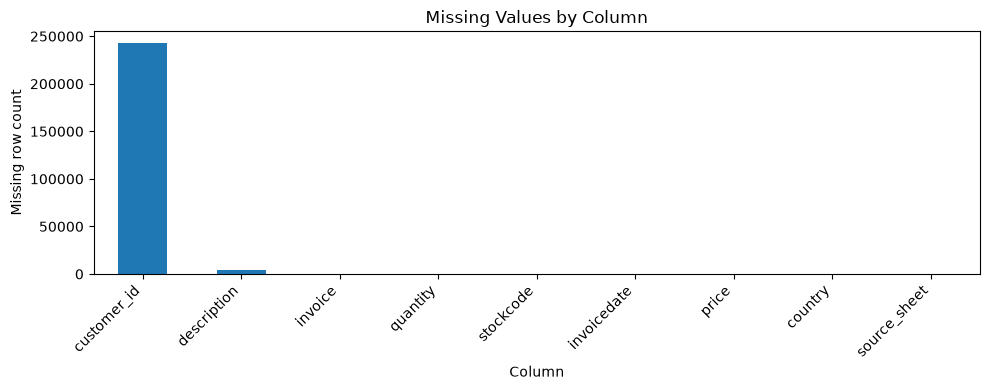

In [5]:
missing_report["missing_count"].plot(
    kind="bar",
    figsize=(10, 4),
    title="Missing Values by Column"
)
plt.ylabel("Missing row count")
plt.xlabel("Column")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 5. Investigate missing Customer IDs and descriptions


In [6]:
missing_customer_count = df["customer_id"].isna().sum()
missing_description_count = df["description"].isna().sum()

print("Missing Customer IDs:", missing_customer_count)
print("Missing descriptions:", missing_description_count)

display(
    df.loc[df["customer_id"].isna(),
           ["invoice", "stockcode", "description", "quantity", "price"]].head(10)
)

Missing Customer IDs: 243007
Missing descriptions: 4382


,invoice,stockcode,description,quantity,price
263,489464,21733,85123a mixed,-96,0.00
283,489463,71477,short,-240,0.00
284,489467,85123A,21733 mixed,-192,0.00
470,489521,21646,<NA>,-50,0.00
577,489525,85226C,BLUE PULL BACK RACING CAR,1,0.55
578,489525,85227,SET/6 3D KIT CARDS FOR KIDS,1,0.85
1055,489548,22271,FELTCRAFT DOLL ROSIE,1,2.95
1056,489548,22254,FELT TOADSTOOL LARGE,12,1.25
1057,489548,22273,FELTCRAFT DOLL MOLLY,3,2.95
1058,489548,22195,LARGE HEART MEASURING SPOONS,1,1.65


In [7]:
# StockCode-description pairs where description is present.
valid_descriptions = df.loc[
    df["stockcode"].notna() & df["description"].notna(),
    ["stockcode", "description"]
].copy()

# Suspicious descriptions are operational notes, not reliable product names.
suspicious_terms = [
    "damaged", "missing", "found by", "wet/rusty", "thrown away",
    "sold as", "rex use", "can't sell", "cannot sell", "disposed"
]

description_lower = valid_descriptions["description"].str.lower()

suspicious_mask = description_lower.apply(
    lambda value: any(term in value for term in suspicious_terms)
)

valid_descriptions = valid_descriptions.loc[~suspicious_mask].copy()

# Count unique reliable descriptions per StockCode.
description_counts = (
    valid_descriptions.groupby("stockcode")["description"].nunique()
)

single_description_codes = description_counts[
    description_counts == 1
].index

description_mapping = (
    valid_descriptions[
        valid_descriptions["stockcode"].isin(single_description_codes)
    ]
    .drop_duplicates(subset=["stockcode", "description"])
    .groupby("stockcode")["description"]
    .first()
)

print("StockCodes with one reliable description:", len(description_mapping))
print("Suspicious description rows excluded from mapping:", suspicious_mask.sum())

StockCodes with one reliable description: 3711
Suspicious description rows excluded from mapping: 216


In [8]:
# Fill only missing descriptions and only when a safe mapping exists.
missing_description_mask = df["description"].isna()

df.loc[missing_description_mask, "description"] = (
    df.loc[missing_description_mask, "stockcode"].map(description_mapping)
)

filled_description_count = (
    missing_description_count - df["description"].isna().sum()
)

print("Descriptions filled:", filled_description_count)
print("Descriptions still missing:", df["description"].isna().sum())

Descriptions filled: 3186
Descriptions still missing: 1196


## 6. Duplicate transaction investigation and handling


In [9]:
duplicate_columns = [
    "invoice", "stockcode", "description", "quantity",
    "invoicedate", "price", "customer_id", "country"
]

duplicate_mask = df.duplicated(
    subset=duplicate_columns,
    keep=False
)

duplicate_candidate_rows = df.loc[duplicate_mask].copy()
duplicate_rows_to_remove = df.duplicated(
    subset=duplicate_columns,
    keep="first"
).sum()

print("Rows belonging to duplicate groups:", len(duplicate_candidate_rows))
print("Exact duplicate rows beyond first occurrence:", duplicate_rows_to_remove)

display(
    duplicate_candidate_rows.sort_values(
        ["invoice", "stockcode"], na_position="last"
    ).head(20)
)

duplicate_candidate_rows.to_csv(
    INTERIM_DIR / "duplicate_transaction_candidates.csv",
    index=False
)

Rows belonging to duplicate groups: 67242
Exact duplicate rows beyond first occurrence: 34335


,invoice,stockcode,description,quantity,invoicedate,price,customer_id,country,source_sheet
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329,United Kingdom,Year 2009-2010
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329,United Kingdom,Year 2009-2010
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329,United Kingdom,Year 2009-2010
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329,United Kingdom,Year 2009-2010
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329,United Kingdom,Year 2009-2010
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329,United Kingdom,Year 2009-2010
394,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329,United Kingdom,Year 2009-2010
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329,United Kingdom,Year 2009-2010
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329,United Kingdom,Year 2009-2010
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329,United Kingdom,Year 2009-2010


In [10]:
rows_before_deduplication = len(df)

df = df.drop_duplicates(
    subset=duplicate_columns,
    keep="first"
).copy()

rows_after_deduplication = len(df)

print("Rows before duplicate removal:", rows_before_deduplication)
print("Rows after duplicate removal:", rows_after_deduplication)
print("Rows removed:", rows_before_deduplication - rows_after_deduplication)

Rows before duplicate removal: 1067371
Rows after duplicate removal: 1033036
Rows removed: 34335


## 7. Identify cancellations and returns

Source convention ke according invoice ID `C` se start hone par cancellation flag set karenge. Non-cancellation invoice ke negative quantity records ko return category denge.

Cancellation aur return records preserve honge. Unhe delete nahi karenge; RFM eligibility ke liye alag flag use hoga.

In [11]:
df["is_cancelled"] = (
    df["invoice"].str.startswith("C", na=False)
)

conditions = [
    df["is_cancelled"],
    (df["quantity"] < 0) & (~df["is_cancelled"])
]

choices = ["cancellation", "return"]

df["transaction_type"] = np.select(
    conditions,
    choices,
    default="normal_sale"
)

print("Transaction rows by type:")
display(df["transaction_type"].value_counts().to_frame("row_count"))

cancelled_rows = df.loc[df["is_cancelled"]]
print("Cancellation rows:", len(cancelled_rows))
print("Unique cancelled invoices:", cancelled_rows["invoice"].nunique())
print("Negative quantity rows:", (df["quantity"] < 0).sum())

Transaction rows by type:


,row_count
transaction_type,
normal_sale,1010539
cancellation,19104
return,3393


Cancellation rows: 19104
Unique cancelled invoices: 8292
Negative quantity rows: 22496


In [12]:
# Financial amount for analysis; source rows remain preserved.
df["line_amount"] = df["quantity"] * df["price"]

transaction_amount_report = (
    df.groupby("transaction_type")
    .agg(
        record_count=("invoice", "size"),
        total_quantity=("quantity", "sum"),
        total_amount=("line_amount", "sum")
    )
    .reset_index()
)

display(transaction_amount_report)

transaction_amount_report.to_csv(
    INTERIM_DIR / "transaction_type_summary.csv",
    index=False
)

,transaction_type,record_count,total_quantity,total_amount
0,cancellation,19104,-476819,-1.462051e+06
1,normal_sale,1010539,11455912,2.031758e+07
2,return,3393,-569314,0.000000e+00


## 8. Validate quantity and price

In [13]:
price_quantity_report = pd.DataFrame({
    "check": [
        "Missing quantity",
        "Zero quantity",
        "Negative quantity",
        "Missing price",
        "Zero price",
        "Negative price"
    ],
    "row_count": [
        df["quantity"].isna().sum(),
        (df["quantity"] == 0).sum(),
        (df["quantity"] < 0).sum(),
        df["price"].isna().sum(),
        (df["price"] == 0).sum(),
        (df["price"] < 0).sum()
    ]
})

display(price_quantity_report)
price_quantity_report.to_csv(
    INTERIM_DIR / "quantity_price_validation.csv",
    index=False
)

,check,row_count
0,Missing quantity,0
1,Zero quantity,0
2,Negative quantity,22496
3,Missing price,0
4,Zero price,6014
5,Negative price,5


In [14]:
negative_price_records = df.loc[df["price"] < 0].copy()

print("Negative-price records:", len(negative_price_records))
display(
    negative_price_records[
        ["invoice", "stockcode", "description", "quantity",
         "invoicedate", "price", "customer_id"]
    ]
)

zero_price_normal_sales = df.loc[
    (df["transaction_type"] == "normal_sale") &
    (df["price"] == 0)
]

print("Zero-price normal-sale rows:", len(zero_price_normal_sales))

Negative-price records: 5


,invoice,stockcode,description,quantity,invoicedate,price,customer_id
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,<NA>
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,<NA>
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,<NA>
825444,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,<NA>
825445,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,<NA>


Zero-price normal-sale rows: 2621


## 9. Create RFM eligibility flag


In [15]:
df["is_zero_price"] = df["price"].eq(0)
df["is_negative_price"] = df["price"].lt(0)
df["is_customer_id_missing"] = df["customer_id"].isna()

df["is_rfm_eligible"] = (
    (df["transaction_type"] == "normal_sale") &
    (df["quantity"] > 0) &
    (df["price"] > 0) &
    (df["customer_id"].notna()) &
    (df["invoicedate"].notna())
)

print("Total rows:", len(df))
print("RFM eligible rows:", int(df["is_rfm_eligible"].sum()))
print("Cancellation rows:", int(df["is_cancelled"].sum()))
print("Return rows:", int((df["transaction_type"] == "return").sum()))
print("Missing Customer IDs:", int(df["customer_id"].isna().sum()))

Total rows: 1033036
RFM eligible rows: 779425
Cancellation rows: 19104
Return rows: 3393
Missing Customer IDs: 235151


## 10. Build final data-quality report


In [16]:
final_quality_report = pd.DataFrame({
    "metric": [
        "total_rows_after_cleaning",
        "total_columns",
        "missing_customer_ids",
        "missing_descriptions",
        "exact_duplicate_rows_removed",
        "cancellation_rows",
        "return_rows",
        "normal_sale_rows",
        "zero_price_rows",
        "negative_price_rows",
        "invalid_invoice_dates",
        "rfm_eligible_rows"
    ],
    "value": [
        len(df),
        len(df.columns),
        int(df["customer_id"].isna().sum()),
        int(df["description"].isna().sum()),
        int(rows_before_deduplication - rows_after_deduplication),
        int((df["transaction_type"] == "cancellation").sum()),
        int((df["transaction_type"] == "return").sum()),
        int((df["transaction_type"] == "normal_sale").sum()),
        int(df["price"].eq(0).sum()),
        int(df["price"].lt(0).sum()),
        int(df["invoicedate"].isna().sum()),
        int(df["is_rfm_eligible"].sum())
    ]
})

display(final_quality_report)

final_quality_report.to_csv(
    INTERIM_DIR / "final_data_quality_report.csv",
    index=False
)

,metric,value
0,total_rows_after_cleaning,1033036
1,total_columns,16
2,missing_customer_ids,235151
3,missing_descriptions,1181
4,exact_duplicate_rows_removed,34335
5,cancellation_rows,19104
6,return_rows,3393
7,normal_sale_rows,1010539
8,zero_price_rows,6014
9,negative_price_rows,5


## 11. Export cleaned transactions as CSV

In [17]:
CLEANED_FILE = INTERIM_DIR / "cleaned_transactions.csv"

df.to_csv(CLEANED_FILE, index=False)

print("Cleaned CSV saved at:", CLEANED_FILE)
print("Saved rows:", len(df))
print("Saved columns:", len(df.columns))

Cleaned CSV saved at: d:\loyality_reward_optimization\data\interim\cleaned_transactions.csv
Saved rows: 1033036
Saved columns: 16


## 12. Reload and validate the exported CSV


In [18]:
cleaned_check = pd.read_csv(
    CLEANED_FILE,
    dtype={"invoice": "string", "stockcode": "string"}
)

checks = {
    "row_count_matches": len(cleaned_check) == len(df),
    "column_names_match": list(cleaned_check.columns) == list(df.columns),
    "rfm_eligible_count_matches": (
        int(cleaned_check["is_rfm_eligible"].sum()) ==
        int(df["is_rfm_eligible"].sum())
    ),
    "line_amount_total_matches": np.isclose(
        cleaned_check["line_amount"].sum(),
        df["line_amount"].sum(),
        rtol=1e-9,
        atol=1e-6
    )
}

for check_name, passed in checks.items():
    print(f"{check_name}: {'PASSED' if passed else 'FAILED'}")

if not all(checks.values()):
    raise ValueError("CSV validation failed. Check the report above.")

print("\nCSV validation: PASSED")
print("Final CSV shape:", cleaned_check.shape)

row_count_matches: PASSED
column_names_match: PASSED
rfm_eligible_count_matches: PASSED
line_amount_total_matches: PASSED

CSV validation: PASSED
Final CSV shape: (1033036, 16)


## 13. Final Summary and Expected Outputs

By the end of this notebook, the following output files should be generated:

- `data/interim/cleaned_transactions.csv`
- `data/interim/initial_missing_values_report.csv`
- `data/interim/duplicate_transaction_candidates.csv`
- `data/interim/transaction_type_summary.csv`
- `data/interim/quantity_price_validation.csv`
- `data/interim/final_data_quality_report.csv`

These files will help maintain a structured record of the data cleaning process, data quality checks, and validation results.

### Next Notebook: `03_eda.ipynb`

In the next notebook, we will perform Exploratory Data Analysis (EDA) using the cleaned transactions dataset.

The analysis will cover:

- **Monthly Sales Analysis:** Analyze sales trends and revenue patterns over time.
- **Country-wise Sales Analysis:** Identify countries contributing the most to total sales.
- **Product Trends:** Analyze top-selling products and product performance.
- **Customer Behaviour Analysis:** Understand customer purchasing patterns and transaction behaviour.

### RFM Implementation Reminder

As per the main project brief, the RFM analysis must follow these conventions:

1. **Fixed Historical Reference Date:** Use a fixed reference date calculated as one day after the latest qualifying purchase date instead of using the current date.

2. **Frequency Calculation:** Clearly document the invoice-counting convention used to calculate customer purchase frequency.

3. **Monetary Calculation:** Clearly document whether Monetary value is calculated using gross revenue or net revenue.

These conventions will ensure consistency, reproducibility, and accuracy throughout the RFM analysis.